# 1.0 · Exploración de los datos de MiBici 2025 (Johanna Camargo)

Notebook **solo de exploración**: toda la lógica reutilizable vive en el paquete `mibici`
(`dataset.py`, `features.py`, `modeling/`). Requiere haber ejecutado antes `python -m mibici.dataset`.

Objetivo: entender el volumen, la estacionalidad y la autocorrelación de la demanda para justificar
las decisiones de P1 (granularidad estación × día, horizonte de un día, rezagos de 1, 2, 7 y 14 días).

In [1]:
%matplotlib inline
import json
import matplotlib.pyplot as plt
import pandas as pd

from mibici.config import ESTACIONES_PARQUET, MANIFEST_PATH, VIAJES_PARQUET, P1_TRAIN_START, P1_TEST_END
from mibici.features import p1_construir_panel_diario

manifest = json.loads(MANIFEST_PATH.read_text())
viajes = pd.read_parquet(VIAJES_PARQUET)
estaciones = pd.read_parquet(ESTACIONES_PARQUET)
print("data_version:", manifest["data_version"])
print(f"viajes: {len(viajes):,} | estaciones en nomenclatura: {len(estaciones)}")
viajes.head()

data_version: 7aa5e436d887
viajes: 4,532,032 | estaciones en nomenclatura: 484


,viaje_id,inicio_viaje,fin_viaje,origen_id,destino_id,mes_archivo
0,37162342,2025-01-01 00:00:44,2025-01-01 00:11:29,211,395,2025_01
1,37162343,2025-01-01 00:04:11,2025-01-01 00:15:07,35,260,2025_01
2,37162344,2025-01-01 00:05:27,2025-01-01 00:15:23,35,260,2025_01
3,37162345,2025-01-01 00:07:47,2025-01-01 00:17:42,190,11,2025_01
4,37162346,2025-01-01 00:08:52,2025-01-01 00:18:10,273,8,2025_01


## 1. Calidad básica: nulos y duraciones

In [2]:
dur_min = (viajes["fin_viaje"] - viajes["inicio_viaje"]).dt.total_seconds() / 60
resumen = pd.Series({
    "fechas de inicio nulas": viajes["inicio_viaje"].isna().sum(),
    "duración < 1 min": (dur_min < 1).sum(),
    "duración > 24 h": (dur_min > 24 * 60).sum(),
    "duración negativa": (dur_min < 0).sum(),
    "mediana de duración (min)": round(dur_min.median(), 1),
})
resumen

fechas de inicio nulas            0.0
duración < 1 min             117226.0
duración > 24 h                   6.0
duración negativa                 0.0
mediana de duración (min)         9.6
dtype: float64

**Lectura:** los viajes de menos de 1 minuto (desanclajes fallidos) y de más de 24 horas son pocos y no
representan demanda real; los pipelines de P1, P2 y P3 los descartan con el mismo criterio (60 s – 24 h).

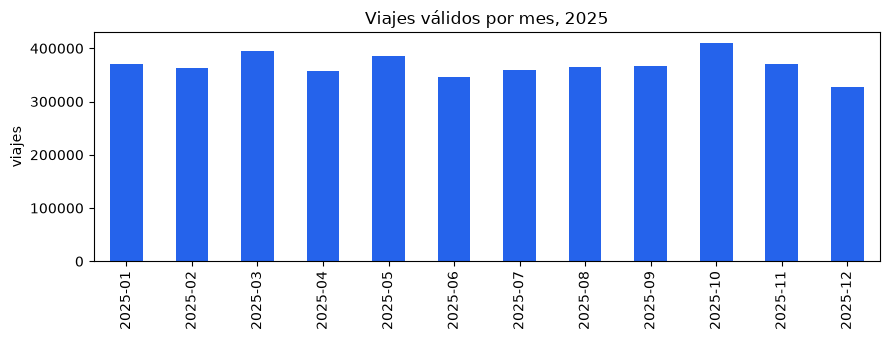

In [3]:
validos = viajes.loc[dur_min.between(1, 24 * 60)]
por_mes = validos.groupby(validos["inicio_viaje"].dt.to_period("M")).size()
ax = por_mes.plot(kind="bar", figsize=(9, 3.5), color="#2563eb")
ax.set_title("Viajes válidos por mes, 2025"); ax.set_ylabel("viajes"); ax.set_xlabel("")
plt.tight_layout()

## 2. Patrón horario y semanal

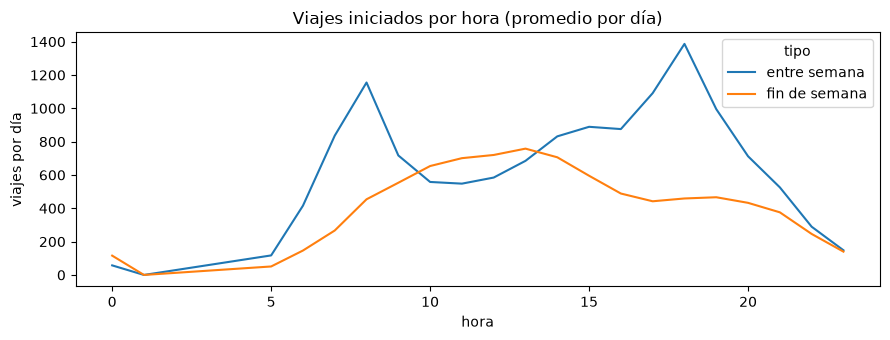

In [4]:
h = validos.assign(hora=validos["inicio_viaje"].dt.hour,
                  tipo=(validos["inicio_viaje"].dt.dayofweek >= 5).map({False: "entre semana", True: "fin de semana"}))
dias = h.groupby("tipo")["inicio_viaje"].apply(lambda s: s.dt.normalize().nunique())
perfil = h.groupby(["tipo", "hora"]).size().unstack(0) / dias
ax = perfil.plot(figsize=(9, 3.5)); ax.set_title("Viajes iniciados por hora (promedio por día)")
ax.set_ylabel("viajes por día"); plt.tight_layout()

**Lectura:** entre semana hay picos de traslado (≈8 h y ≈18 h); en fin de semana el uso es menor y más
plano. Por eso P1 incluye `dia_semana`, `fin_semana` y `feriado`.

## 3. Demanda diaria por estación (variable objetivo de P1)

In [5]:
panel = p1_construir_panel_diario(validos, P1_TRAIN_START, P1_TEST_END)
print(f"filas estación-día: {len(panel):,} | estaciones: {panel.index.get_level_values(0).nunique()}")
panel["viajes"].describe(percentiles=[.25, .5, .75, .95]).round(1)

filas estación-día: 134,621 | estaciones: 371


count    134621.0
mean         32.8
std          33.5
min           0.0
25%          11.0
50%          23.0
75%          44.0
95%          89.0
max         550.0
Name: viajes, dtype: float64

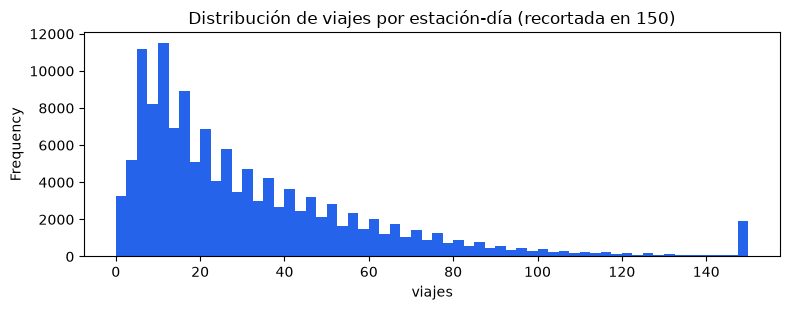

In [6]:
ax = panel["viajes"].clip(upper=150).plot(kind="hist", bins=60, figsize=(8, 3.2), color="#2563eb")
ax.set_title("Distribución de viajes por estación-día (recortada en 150)"); ax.set_xlabel("viajes")
plt.tight_layout()

**Lectura:** la variable es un conteo no negativo y muy asimétrico (muchas estaciones con pocos viajes y
unas cuantas con más de 100 al día). Esto justifica una pérdida **Poisson** y métricas robustas como el MAE y el WAPE.

## 4. Autocorrelación de la demanda diaria (justifica los rezagos de P1)

1     0.365
2     0.021
3    -0.094
4    -0.106
5    -0.029
6     0.253
7     0.590
8     0.239
9    -0.061
10   -0.174
11   -0.177
12   -0.085
13    0.225
14    0.551
dtype: float64

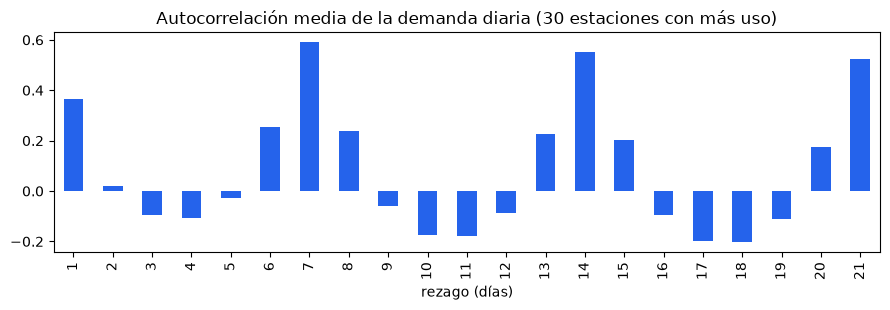

In [7]:
top = panel.groupby(level=0)["viajes"].sum().nlargest(30).index
acf = {}
for est in top:
    s = panel.loc[est, "viajes"]
    acf[est] = [s.autocorr(lag) for lag in range(1, 22)]
acf = pd.DataFrame(acf, index=range(1, 22)).mean(axis=1)
ax = acf.plot(kind="bar", figsize=(9, 3.2), color="#2563eb")
ax.set_title("Autocorrelación media de la demanda diaria (30 estaciones con más uso)")
ax.set_xlabel("rezago (días)"); plt.tight_layout()
acf.round(3).head(14)

**Lectura:** la autocorrelación más alta está en los rezagos de **7 y 14 días** (≈0.59 y ≈0.55: mismo día de
semanas anteriores) y es moderada en 1 día (≈0.37). Por eso el baseline natural es el ingenuo estacional
`t − 7` y el modelo usa los rezagos 1, 2, 7 y 14 más medias móviles de 7 y 28 días, todos anteriores al día que se predice.

## 5. Estaciones: capacidad y estaciones nuevas

In [8]:
primera = panel.reset_index().groupby("estacion")["fecha"].min()
print("estaciones que inician después de enero:", (primera > "2025-01-31").sum())
print("capacidad (dpcapacity):"); estaciones["dpcapacity"].describe().round(1)

estaciones que inician después de enero: 3
capacidad (dpcapacity):


count    484.0
mean      16.9
std        4.1
min        0.0
25%       15.0
50%       15.0
75%       19.0
max       39.0
Name: dpcapacity, dtype: float64

**Conclusiones para el pipeline**

* Granularidad estación × día y horizonte de un día (la predicción del día D se emite al cierre de D-1).
* Partición temporal: TRAIN ene-sep, VAL oct (selección del modelo) y TEST nov-dic 2025.
* Las estaciones nuevas solo entran al panel desde su primera actividad; las filas sin 28 días de historia se descartan.
* Baseline: ingenuo semanal; candidatos: regresión Poisson lineal y gradient boosting Poisson.